# Right-Turning Crash Severity Analysis
## Milestone 3: Testing and validation
This notebook validates the initial prototype analyzing right-turn crash severity and speed limits. Run from the repository root or from its notebook location. The source CSV is not modified.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'data' / 'right_turn_crashes.csv').exists():
    root = root.parent
csv_path = root / 'data' / 'right_turn_crashes.csv'
assert csv_path.exists(), f'CSV not found: {csv_path}'
print('Repository:', root)
print('Dataset:', csv_path)

Repository: C:\Users\meherins\OneDrive - Michigan State University\Documents\GitHub\crash-severity-analysis
Dataset: C:\Users\meherins\OneDrive - Michigan State University\Documents\GitHub\crash-severity-analysis\data\right_turn_crashes.csv


### Load data and verify required columns

In [2]:
df = pd.read_csv(csv_path)
required = {'CrashSeverity', 'SpeedLimit'}
missing = required - set(df.columns)
assert not missing, f'Missing required columns: {sorted(missing)}'
print('Total rows:', len(df))
print('Missing values in required columns:')
print(df[['CrashSeverity', 'SpeedLimit']].isna().sum())
print('Duplicate rows (diagnostic only):', df.duplicated().sum())
display(df.head())

Total rows: 1683
Missing values in required columns:
CrashSeverity    2
SpeedLimit       2
dtype: int64
Duplicate rows (diagnostic only): 0


,OBJECTID,Join_Count,TARGET_FID,Join_Count_1,TARGET_FID_1,CrashNum,Street1,Street1Other,Street1Located,Street2,...,RoadIntersectionType,RoadEnvironment,SignalControl.1,CrashTime,VehCrashType.1,Weather.1,PedestrianInvolved.1,NumVehicles.1,DriverLevelFactors,CrashSeverity
0,1.0,4.0,39150.0,1.0,1.0,LVM230200065797,OTHER,N RANCHO DR,SR599S,OTHER,...,1.0,0.0,0.0,3.0,1.0,1.0,0.0,1.0,0.0,Injury
1,2.0,12.0,56889.0,1.0,2.0,LVM230200085193,HINSON ST,NaN,HINSON ST,SUNSET RD,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,No injury
2,3.0,3.0,65808.0,1.0,3.0,HP23-03623,S AMIGO ST,NaN,S AMIGO ST,ST ROSE PKWY,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,Injury
3,4.0,13.0,39731.0,1.0,4.0,LVM220800042360,S LAS VEGAS BLVD,NaN,S LAS VEGAS BLVD,RESORT WORLD DR,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,Injury
4,5.0,3.0,37402.0,1.0,5.0,LVM220400075820,S LAS VEGAS BLVD,NaN,S LAS VEGAS BLVD,W WIGWAM AVE,...,1.0,1.0,1.0,2.0,1.0,0.0,0.0,1.0,0.0,Injury


### Clean some variables (i.e., crash severity and speed limit) used for this validation
Missing severity, missing speed, and speed limits less than 0 are excluded from these summaries only. Duplicate rows are flagged but not automatically removed because two crashes may share identical recorded attributes.

In [9]:
import pandas as pd

# Create a copy of the original dataset
clean = df.copy()

# Clean crash severity values
clean["CrashSeverity"] = (
    clean["CrashSeverity"]
    .astype("string")
    .str.strip()
)

# Clean speed limit categories
clean["SpeedLimit"] = (
    clean["SpeedLimit"]
    .astype("string")
    .str.strip()
)

# Define valid speed limit categories
valid_speed_limits = [
    "25 mph or less",
    "30 or 35 mph",
    "40 mph or more"
]

# Define valid crash severity categories
valid_severity = [
    "Injury",
    "No injury"
]

# Identify valid observations
valid = (
    clean["SpeedLimit"].isin(valid_speed_limits)
    & clean["CrashSeverity"].isin(valid_severity)
)

# Retain valid observations
clean = clean.loc[valid].copy()

# Display data cleaning results
print("Original rows:", len(df))
print("Valid rows:", len(clean))
print("Excluded rows:", len(df) - len(clean))

print(
    "Retained percent:",
    round(100 * len(clean) / len(df), 2)
    if len(df) else "N/A"
)

assert len(clean) > 0, "No valid observations for analysis"

print("\nData cleaning completed successfully.")
display(clean.head())

Original rows: 1683
Valid rows: 1681
Excluded rows: 2
Retained percent: 99.88

Data cleaning completed successfully.


,OBJECTID,Join_Count,TARGET_FID,Join_Count_1,TARGET_FID_1,CrashNum,Street1,Street1Other,Street1Located,Street2,...,RoadIntersectionType,RoadEnvironment,SignalControl.1,CrashTime,VehCrashType.1,Weather.1,PedestrianInvolved.1,NumVehicles.1,DriverLevelFactors,CrashSeverity
0,1.0,4.0,39150.0,1.0,1.0,LVM230200065797,OTHER,N RANCHO DR,SR599S,OTHER,...,1.0,0.0,0.0,3.0,1.0,1.0,0.0,1.0,0.0,Injury
1,2.0,12.0,56889.0,1.0,2.0,LVM230200085193,HINSON ST,NaN,HINSON ST,SUNSET RD,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,No injury
2,3.0,3.0,65808.0,1.0,3.0,HP23-03623,S AMIGO ST,NaN,S AMIGO ST,ST ROSE PKWY,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,Injury
3,4.0,13.0,39731.0,1.0,4.0,LVM220800042360,S LAS VEGAS BLVD,NaN,S LAS VEGAS BLVD,RESORT WORLD DR,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,Injury
4,5.0,3.0,37402.0,1.0,5.0,LVM220400075820,S LAS VEGAS BLVD,NaN,S LAS VEGAS BLVD,W WIGWAM AVE,...,1.0,1.0,1.0,2.0,1.0,0.0,0.0,1.0,0.0,Injury


### Calculate crash severity by speed limit

In [10]:
severity_by_speed = pd.crosstab(
    clean["SpeedLimit"],
    clean["CrashSeverity"]
)

speed_order = [
    "25 mph or less",
    "30 or 35 mph",
    "40 mph or more"
]

severity_by_speed = severity_by_speed.reindex(
    speed_order,
    fill_value=0
)

print("Crash severity by speed limit:")
display(severity_by_speed)

Crash severity by speed limit:


CrashSeverity,Injury,No injury
SpeedLimit,,
25 mph or less,247,166
30 or 35 mph,331,333
40 mph or more,335,269


### Validate severity and speed-limit summary

In [11]:
# Test 1: Cleaned data is not empty
assert len(clean) > 0

# Test 2: No missing values in required variables
assert clean["CrashSeverity"].notna().all()
assert clean["SpeedLimit"].notna().all()

# Test 3: All speed limit categories are valid
assert clean["SpeedLimit"].isin(speed_order).all()

# Test 4: All crash severity values are valid
assert clean["CrashSeverity"].isin(
    ["Injury", "No injury"]
).all()

# Test 5: Cross-tabulation totals match cleaned dataset
assert severity_by_speed.to_numpy().sum() == len(clean)

print("All five validation checks passed!")

All five validation checks passed!


### Plot crash severity by speed limit

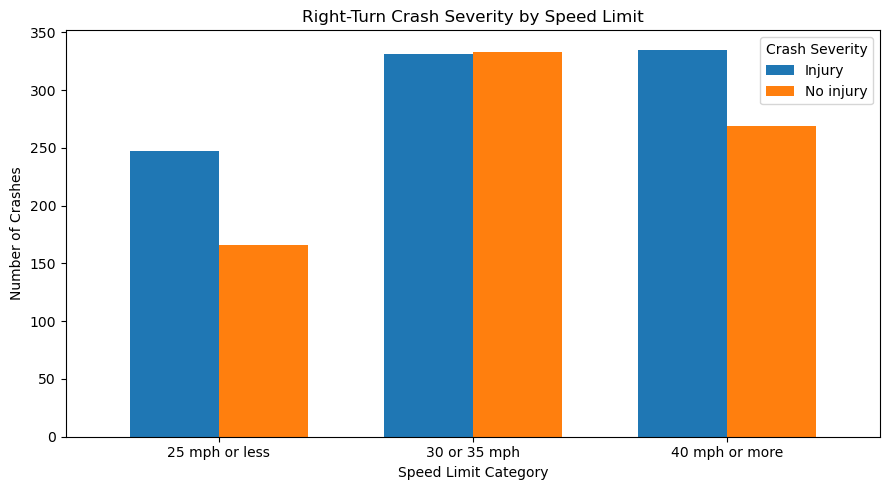

In [12]:
import matplotlib.pyplot as plt

ax = severity_by_speed.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.xlabel("Speed Limit Category")
plt.ylabel("Number of Crashes")
plt.title("Right-Turn Crash Severity by Speed Limit")

plt.xticks(rotation=0)
plt.legend(title="Crash Severity")

plt.tight_layout()
plt.show()

### Run reproducible automated tests
The test file `test_validation.py` is stored at the repository.

In [13]:
import sys
import subprocess
from pathlib import Path

# Find repository
root = Path.cwd().resolve()

if not (root / "test_validation.py").exists():
    root = root.parent

test_file = root / "test_validation.py"

assert test_file.exists(), (
    f"Test file not found: {test_file}"
)

print("Running automated validation tests...\n")

# Run pytest using the current Python environment
result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        str(test_file)
    ],
    cwd=root,
    capture_output=True,
    text=True
)

# Display results
print(result.stdout)

if result.stderr:
    print(result.stderr)

# Verify tests passed
assert result.returncode == 0, (
    "One or more automated tests failed."
)

print("\nAll automated validation tests passed!")

Running automated validation tests...

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- C:\Users\meherins\AppData\Local\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\meherins\OneDrive - Michigan State University\Documents\GitHub\crash-severity-analysis
plugins: anyio-4.7.0
collecting ... collected 9 items

test_validation.py::test_required_columns PASSED                         [ 11%]
test_validation.py::test_valid_rows_retained PASSED                      [ 22%]
test_validation.py::test_invalid_rows_excluded PASSED                    [ 33%]
test_validation.py::test_whitespace_is_removed PASSED                    [ 44%]
test_validation.py::test_severity_counts PASSED                          [ 55%]
test_validation.py::test_cross_tabulation PASSED                         [ 66%]
test_validation.py::test_summary_totals PASSED                           [ 77%]
test_validation.py::t

## 6. Interpretation and limitations
- The tests establish consistency of the implemented summary calculations, not accuracy of source crash reports.
- Invalid or missing speed limits and severity values are excluded from these particular summaries; counts of exclusions are reported.
- Duplicate rows are reported, not removed, because duplicated attribute values do not necessarily indicate duplicated crashes.
- Crash frequencies are not crash rates: roadway exposure, traffic volumes, and confounding factors are not controlled.
- No causal interpretation of speed limit and crash severity is justified by these plots.